# Pemodelan RDA Penyebaran Karhutla Gambut Kalimantan (kode lengkap)

Satu berkas berisi seluruh alur: pembaca GRIB, model **Reaction–Diffusion–Advection (RDA)**
dengan skema beda hingga, eksperimen simulasi sintetis, dan validasi terhadap hotspot VIIRS
dengan angin + kelembapan tanah ERA5.

**Letakkan berkas data di folder yang sama dengan berkas ini:**

| Berkas | Isi | Dipakai untuk |
|---|---|---|
| `data.grib` | ERA5 angin 10 m (u10, v10) + suhu 2 m, per jam, 1 Jul–12 Sep 2026 | simulasi sintetis |
| `data_1.grib` | ERA5 angin 100 m (u100, v100), per jam, 1–30 Sep 2026 | validasi |
| `data_c11eca.grib` | ERA5 `volumetric_soil_water_layer_1`, per jam, 1–30 Sep 2026 | validasi |
| `sebaran-hotspot*.csv` | hotspot VIIRS NOAA-20 (pemisah `;`, desimal `,`) | validasi |
| `Indonesia_peat_lands.csv` | atribut poligon gambut (tanpa koordinat) | ringkasan saja |

**Pustaka:** `numpy pandas scipy matplotlib` (lihat `requirements.txt`). Tidak perlu `eccodes`/`cfgrib`.

**Cara pakai:** di notebook jalankan sel dari atas ke bawah. Di terminal: `python rda_karhutla_lengkap.py --stage semua`
(opsi `--stage gambut|sintetis|validasi`, `--cepat` untuk uji singkat dengan grid parameter kecil).

**Persamaan model**

$$\frac{\partial F}{\partial t}+U\frac{\partial F}{\partial x}+V\frac{\partial F}{\partial y}=\nabla\cdot(D\nabla F)+r\,e^{-\alpha m}F\left(1-\frac{F}{K}\right)+s_0\,e^{-\alpha m}\,(G_\sigma * F)\left(1-\frac{F}{K}\right)$$

Suku terakhir (penyalaan baru nonlokal) hanya dipakai pada tahap validasi.

In [1]:
# ============================== 0. IMPOR & KONFIGURASI ==============================
import os, sys, json, itertools, datetime as dt, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter, map_coordinates, binary_dilation

IN_NOTEBOOK = "ipykernel" in sys.modules
import matplotlib
if not IN_NOTEBOOK:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)

BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
OUT_DIR = BASE_DIR / "hasil"
OUT_DIR.mkdir(exist_ok=True)

# Nama berkas data (ubah di sini bila namamu berbeda; boleh pakai pola glob)
NAMA_BERKAS = dict(
    angin10="data.grib",
    angin100="data_1.grib",
    sm="data_c11eca.grib",
    gambut="Indonesia_peat_lands.csv",
    hotspot="sebaran-hotspot*.csv",
)

def cari_berkas(kunci):
    """Cari berkas data di BASE_DIR (pola glob dipilih yang terbesar)."""
    kand = sorted(BASE_DIR.glob(NAMA_BERKAS[kunci]), key=lambda p: p.stat().st_size, reverse=True)
    if not kand:
        raise FileNotFoundError(f"Berkas '{NAMA_BERKAS[kunci]}' tidak ditemukan di {BASE_DIR}")
    return kand[0]

def simpan_gambar(fig, nama):
    p = OUT_DIR / nama
    fig.savefig(p, dpi=150, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)
    print("  gambar:", p.name)

print("Folder kerja :", BASE_DIR)
print("Folder hasil :", OUT_DIR)

Folder kerja : c:\Users\Lenovo\OneDrive\Desktop\문서\materi kuliah\materi kuliah\semester 5\pemodelan matematika\data
Folder hasil : c:\Users\Lenovo\OneDrive\Desktop\문서\materi kuliah\materi kuliah\semester 5\pemodelan matematika\data\hasil


In [2]:
# ============================== 1. PEMBACA GRIB1 (tanpa eccodes) ==============================
def _s(b):
    """Bilangan bertanda sign-magnitude GRIB."""
    v = int.from_bytes(b, "big"); n = len(b) * 8
    return -(v & ~(1 << (n - 1))) if v >> (n - 1) else v

def _ibm(b):
    """Float IBM 32-bit (referensi nilai pada BDS GRIB1)."""
    v = int.from_bytes(b, "big")
    s = -1 if v >> 31 else 1
    return s * (v & 0xFFFFFF) / 16777216.0 * 16.0 ** (((v >> 24) & 0x7F) - 64)

def read_grib1(path):
    """
    Baca GRIB1 (simple packing, grid lat/lon reguler, scan mode 0, tanpa bitmap).
    Return dict {kode_parameter: (waktu[list], lat[S->N], lon[W->E], array[t, lat, lon])}.
    Kode ECMWF tabel 128/228: 165=u10, 166=v10, 167=t2m, 39=swvl1, 246=u100, 247=v100.
    """
    b = Path(path).read_bytes(); pos = 0; rec = []; grid = None
    while True:
        i = b.find(b"GRIB", pos)
        if i < 0:
            break
        L = int.from_bytes(b[i + 4:i + 7], "big"); m = b[i:i + L]; pos = i + L
        p = 8; pl = int.from_bytes(m[p:p + 3], "big"); pds = m[p:p + pl]; p += pl
        flag = pds[7]
        t = dt.datetime(100 * (pds[24] - 1) + pds[12], pds[13], pds[14], pds[15], pds[16])
        dsf = _s(pds[26:28]); prm = pds[8]
        if flag & 0x80:
            gl = int.from_bytes(m[p:p + 3], "big"); g = m[p:p + gl]; p += gl
            assert g[27] == 0, "scan mode != 0 tidak didukung"
            grid = dict(ni=int.from_bytes(g[6:8], "big"), nj=int.from_bytes(g[8:10], "big"),
                        lat1=_s(g[10:13]) / 1e3, lon1=_s(g[13:16]) / 1e3,
                        lat2=_s(g[17:20]) / 1e3, lon2=_s(g[20:23]) / 1e3)
        if flag & 0x40:
            raise NotImplementedError("GRIB dengan bitmap belum didukung")
        bl = int.from_bytes(m[p:p + 3], "big"); bds = m[p:p + bl]
        E = _s(bds[4:6]); ref = _ibm(bds[6:10]); nb = bds[10]; data = bds[11:]
        bits = np.unpackbits(np.frombuffer(data, dtype=np.uint8))
        n = len(bits) // nb
        X = (bits[:n * nb].reshape(n, nb) * (1 << np.arange(nb - 1, -1, -1))).sum(1).astype(float)
        vals = (ref + X * 2.0 ** E) / 10.0 ** dsf
        rec.append((prm, t, vals[:grid["ni"] * grid["nj"]]))
    lat = np.linspace(grid["lat1"], grid["lat2"], grid["nj"])      # N -> S
    lon = np.linspace(grid["lon1"], grid["lon2"], grid["ni"])
    out = {}
    for prm in sorted(set(r[0] for r in rec)):
        rr = sorted([r for r in rec if r[0] == prm], key=lambda r: r[1])
        T = [r[1] for r in rr]
        A = np.stack([r[2].reshape(grid["nj"], grid["ni"]) for r in rr])[:, ::-1, :]   # S -> N
        out[prm] = (T, lat[::-1].copy(), lon, A)
    return out

In [3]:
# ============================== 2. GRID, INTERPOLASI, NUMERIK FDM ==============================
def make_grid(lat0, lat1, lon0, lon1, dlon):
    """Grid model reguler (derajat). dx dalam km (bergantung lintang), dy dalam km."""
    lat = np.arange(lat0, lat1 + 1e-9, dlon); lon = np.arange(lon0, lon1 + 1e-9, dlon)
    LAT, LON = np.meshgrid(lat, lon, indexing="ij")
    dx = 111.32 * np.cos(np.deg2rad(LAT)) * dlon
    dy = 111.32 * dlon
    return lat, lon, LAT, LON, dx, dy

def regrid(field2d, lat_s, lon_s, LAT, LON):
    """Interpolasi bilinear grid sumber -> grid model."""
    iy = (LAT - lat_s[0]) / (lat_s[1] - lat_s[0]); ix = (LON - lon_s[0]) / (lon_s[1] - lon_s[0])
    return map_coordinates(field2d, [iy, ix], order=1, mode="nearest")

def step(F, B, U, V, D, r, alpha, m, K, dx, dy, dt_h, mu, use_fuel, beta=0.004):
    """
    Satu langkah waktu eksplisit (Euler):
      difusi  = beda pusat bentuk fluks (D variabel, muka sel dirata-ratakan), syarat batas fluks nol
      adveksi = upwind orde 1
      reaksi  = logistik r exp(-alpha m) F (1-F/K); opsi bahan bakar B (use_fuel)
    """
    Fp = np.pad(F, 1, mode="edge"); Dp = np.pad(D, 1, mode="edge")
    De = 0.5 * (Dp[1:-1, 1:-1] + Dp[1:-1, 2:]);  Dw = 0.5 * (Dp[1:-1, 1:-1] + Dp[1:-1, :-2])
    Dn = 0.5 * (Dp[1:-1, 1:-1] + Dp[2:, 1:-1]);  Ds = 0.5 * (Dp[1:-1, 1:-1] + Dp[:-2, 1:-1])
    diff = (De * (Fp[1:-1, 2:] - F) - Dw * (F - Fp[1:-1, :-2])) / dx**2 \
         + (Dn * (Fp[2:, 1:-1] - F) - Ds * (F - Fp[:-2, 1:-1])) / dy**2
    dFdx_b = (F - Fp[1:-1, :-2]) / dx; dFdx_f = (Fp[1:-1, 2:] - F) / dx
    dFdy_b = (F - Fp[:-2, 1:-1]) / dy; dFdy_f = (Fp[2:, 1:-1] - F) / dy
    adv = np.where(U > 0, U * dFdx_b, U * dFdx_f) + np.where(V > 0, V * dFdy_b, V * dFdy_f)
    growth = r * np.exp(-alpha * m) * F * (1 - F / K)
    if use_fuel:
        growth = growth * B
        burnout = mu * F * (1 - B)
        B_new = np.clip(B - dt_h * (F / K) * B * beta, 0, 1)
    else:
        burnout = 0.0; B_new = B
    F_new = F + dt_h * (-adv + diff + growth - burnout)
    return np.clip(F_new, 0.0, K), B_new

def cfl_check(D, U, V, dx, dy, dt_h):
    """Bilangan kestabilan eksplisit; keduanya harus < 1."""
    d = float(np.max(dt_h * np.max(D) * (1 / dx**2 + 1 / dy**2) * 2))
    a = float(np.max(dt_h * (np.abs(U) / dx + np.abs(V) / dy)))
    return d, a

In [4]:
# ============================== 3. METRIK EVALUASI ==============================
def iou(A, B):
    u = np.logical_or(A, B).sum()
    return float(np.logical_and(A, B).sum() / u) if u else 1.0

def dice(A, B):
    s = A.sum() + B.sum()
    return float(2 * np.logical_and(A, B).sum() / s) if s else 1.0

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
def mae(a, b):  return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def r2(obs, mod):
    obs = np.asarray(obs); mod = np.asarray(mod)
    ss = np.sum((obs - obs.mean()) ** 2)
    return float(1 - np.sum((obs - mod) ** 2) / ss) if ss else float("nan")

def area_km2(mask_or_F, Fc, dx, dy):
    return float(np.sum((mask_or_F >= Fc) * dx * dy))

In [6]:
# ============================== 4. PETA GAMBUT ==============================
def ringkas_gambut():
    """Ringkasan atribut Indonesia_peat_lands.csv. Berkas ini TIDAK memuat geometri."""
    d = pd.read_csv(cari_berkas("gambut"), encoding="utf-8-sig")
    print(f"Jumlah poligon : {len(d)}")
    if "shape_Area" in d:
        print(f"Total luas     : {d['shape_Area'].sum() / 1e6:,.0f} km²")
    if "layer_revi" in d:
        print(d["layer_revi"].str.strip().replace("", "(kosong)").value_counts().to_string())
    print("Kolom:", list(d.columns))
    print("CATATAN: tidak ada kolom koordinat -> mask G(x,y) harus dibuat dari shapefile/GeoTIFF gambut.")
    return d

def rasterisasi_gambut(shp_path, LAT, LON, kolom="layer_revi", nilai="gambut", simpan_npy=None):
    """
    (OPSIONAL, belum diuji) Rasterisasi shapefile gambut ke grid model -> mask G (0/1).
    Butuh: pip install geopandas rasterio. Contoh:
        G = rasterisasi_gambut("peat.shp", LAT, LON, simpan_npy=BASE_DIR/"mask_gambut.npy")
    """
    import geopandas as gpd
    from rasterio import features
    from rasterio.transform import from_origin
    gdf = gpd.read_file(shp_path).to_crs(4326)
    gdf = gdf[gdf[kolom].astype(str).str.strip().str.lower().str.startswith(nilai)]
    d = LAT[1, 0] - LAT[0, 0]
    tr = from_origin(LON[0, 0] - d / 2, LAT[-1, 0] + d / 2, d, d)
    G = features.rasterize([(geom, 1) for geom in gdf.geometry], out_shape=LAT.shape,
                           transform=tr, fill=0, dtype="uint8")[::-1]     # baris 0 = selatan
    if simpan_npy:
        np.save(simpan_npy, G)
    return G.astype(float)

def buat_mask_gambut(LAT, LON, path_npy=None, seed=7, fraksi=0.45):
    """G(x,y) in {0,1}. Bila path_npy diberikan dipakai; jika tidak -> mask SINTETIS (hanya demonstrasi)."""
    if path_npy is not None and str(path_npy).endswith(".npy"):
        return np.load(path_npy).astype(float)
    rng = np.random.default_rng(seed)
    z = gaussian_filter(rng.standard_normal(LAT.shape), sigma=LAT.shape[0] / 14)
    z = (z - z.mean()) / z.std()
    return (z > np.quantile(z, 1 - fraksi)).astype(float)

In [7]:
# ============================== 5. SIMULASI SINTETIS (eksperimen numerik) ==============================
def simulasi_sintetis(params, g, t_start, days, ignition, n_frames=6, verbose=True):
    """
    Satu simulasi RDA dengan angin ERA5 10 m nyata, mask gambut SINTETIS, kelembapan konstan m_const.
    Satuan internal: km dan jam. Ini eksperimen metode, BUKAN validasi lapangan.
    """
    P = dict(dlon=0.03, dt_h=1.0, K=1.0, Dg=0.05, Dn=0.01, rg=0.05, rn=0.01, alpha=2.0, m_const=0.3,
             kappa=0.01, Fc=0.5, mu=0.01, beta=0.004, use_fuel=True,
             bbox=(-3.0, 6.0, 110.0, 117.0), peat_path=None)
    P.update(params)
    lat, lon, LAT, LON, dx, dy = make_grid(*P["bbox"], P["dlon"])
    G = buat_mask_gambut(LAT, LON, P["peat_path"])
    m = np.full(LAT.shape, float(P["m_const"]))
    D = P["Dg"] * G + P["Dn"] * (1 - G); r = P["rg"] * G + P["rn"] * (1 - G)
    T, lat_s, lon_s, _ = g[165]
    t0 = int((t_start - T[0]).total_seconds() // 3600); n = int(days * 24 / P["dt_h"])
    F = np.zeros(LAT.shape); B = np.ones(LAT.shape)
    for (la, lo, amp, rad) in ignition:                       # titik api awal (Gaussian kecil)
        dd = (LAT - la) ** 2 + (LON - lo) ** 2 + 1e6 * (G < 0.5)   # geser ke sel gambut terdekat
        la, lo = LAT.flat[dd.argmin()], LON.flat[dd.argmin()]
        d2 = ((LAT - la) * 111.32) ** 2 + ((LON - lo) * 111.32 * np.cos(np.deg2rad(la))) ** 2
        F = np.maximum(F, amp * np.exp(-d2 / (2 * rad**2)))
    frames, times = [], []
    save_every = max(1, n // n_frames)
    for k in range(n):
        h = t0 + int(k * P["dt_h"])
        U = P["kappa"] * 3.6 * regrid(g[165][3][h], lat_s, lon_s, LAT, LON)      # m/s -> km/jam, x kappa
        V = P["kappa"] * 3.6 * regrid(g[166][3][h], lat_s, lon_s, LAT, LON)
        if k == 0:
            cd, ca = cfl_check(D, U, V, dx, dy, P["dt_h"])
            if verbose:
                print(f"  CFL difusi={cd:.3f} adveksi={ca:.3f} (harus < 1)")
            assert cd < 1 and ca < 1, "dt terlalu besar"
        F, B = step(F, B, U, V, D, r, P["alpha"], m, P["K"], dx, dy, P["dt_h"], P["mu"], P["use_fuel"], P["beta"])
        if k % save_every == 0 or k == n - 1:
            frames.append(F.copy()); times.append(T[0] + dt.timedelta(hours=h))
    return dict(F=F, frames=frames, times=times, G=G, LAT=LAT, LON=LON, dx=dx, dy=dy, P=P)

def kecepatan_front(frames, times, Fc, dx, dy):
    """Radius ekuivalen R = sqrt(A/pi) dan laju v = dR/dt (km/jam)."""
    R = np.array([np.sqrt(area_km2(f, Fc, dx, dy) / np.pi) for f in frames])
    th = np.array([(t - times[0]).total_seconds() / 3600 for t in times])
    return th, R, np.gradient(R, th)

def jalankan_sintetis(mulai="2026-08-10", hari=14, dlon=0.03):
    """Baseline + sensitivitas kelembapan, angin, parameter (OAT) + twin experiment."""
    print("\n=== TAHAP: simulasi sintetis ===")
    g = read_grib1(cari_berkas("angin10"))
    t_start = dt.datetime.fromisoformat(mulai)
    ign = [(-2.6, 113.4, 1.0, 5.0), (-1.9, 114.3, 1.0, 5.0)]       # titik api awal ilustratif
    base = dict(dlon=dlon); res = {}

    R0 = simulasi_sintetis(base, g, t_start, hari, ign, n_frames=4)
    dx, dy, Fc = R0["dx"], R0["dy"], R0["P"]["Fc"]
    res["baseline_area_km2"] = area_km2(R0["F"], Fc, dx, dy)

    sm = {}
    for m_ in [0.0, 0.2, 0.4, 0.6, 0.8]:
        sm[m_] = area_km2(simulasi_sintetis({**base, "m_const": m_}, g, t_start, hari, ign, verbose=False)["F"], Fc, dx, dy)
    res["area_vs_m"] = sm

    sk = {}
    for k_ in [0.0, 0.002, 0.004, 0.008]:
        R = simulasi_sintetis({**base, "kappa": k_}, g, t_start, hari, ign, verbose=False); w = R["F"]
        cm = (np.sum(w * R["LAT"]) / w.sum(), np.sum(w * R["LON"]) / w.sum()) if w.sum() > 0 else (np.nan, np.nan)
        sk[k_] = dict(area=area_km2(w, Fc, dx, dy), centroid=cm)
    res["wind"] = {str(k): v for k, v in sk.items()}

    sp = {}
    for nm in ["Dg", "rg", "alpha", "kappa"]:
        for f_ in [0.5, 1.5]:
            R = simulasi_sintetis({**base, nm: R0["P"][nm] * f_}, g, t_start, hari, ign, verbose=False)
            sp[f"{nm}x{f_}"] = area_km2(R["F"], Fc, dx, dy)
    res["oat"] = sp

    truth = simulasi_sintetis({**base, "m_const": 0.3, "rg": 0.06}, g, t_start, hari, ign, verbose=False)
    obs = truth["F"] >= Fc; tw = {}
    for lab, pr in {"theta_benar": {"rg": 0.06}, "rg_salah": {"rg": 0.03}, "m_salah": {"rg": 0.06, "m_const": 0.7}}.items():
        R = simulasi_sintetis({**base, **pr}, g, t_start, hari, ign, verbose=False); mod = R["F"] >= Fc
        tw[lab] = dict(IoU=iou(obs, mod), Dice=dice(obs, mod), RMSE=rmse(truth["F"], R["F"]), MAE=mae(truth["F"], R["F"]))
    res["twin"] = tw

    th, Rr, v = kecepatan_front(R0["frames"], R0["times"], Fc, dx, dy)
    res["v_fire_km_per_day_mean"] = float(np.mean(v[1:]) * 24)
    (OUT_DIR / "hasil_sintetis.json").write_text(json.dumps(res, indent=1, default=float))
    print(json.dumps(res, indent=1, default=float))

    ext = [R0["LON"].min(), R0["LON"].max(), R0["LAT"].min(), R0["LAT"].max()]
    fig, ax = plt.subplots(1, len(R0["frames"]), figsize=(4 * len(R0["frames"]), 4), sharey=True)
    for k, (f, t) in enumerate(zip(R0["frames"], R0["times"])):
        ax[k].imshow(R0["G"], origin="lower", extent=ext, cmap="Greens", alpha=0.35)
        ax[k].imshow(np.ma.masked_less(f, 0.05), origin="lower", extent=ext, cmap="YlOrRd", vmin=0, vmax=1)
        ax[k].contour(R0["LON"], R0["LAT"], f, levels=[Fc], colors="k", linewidths=0.8)
        ax[k].set_title(t.strftime("%d %b %H:%M")); ax[k].set_xlabel("Bujur")
    ax[0].set_ylabel("Lintang"); fig.tight_layout(); simpan_gambar(fig, "fig1_front_sintetis.png")

    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    ax[0].plot(list(sm), list(sm.values()), "o-"); ax[0].set_xlabel("m"); ax[0].set_ylabel("Luas terbakar (km²)")
    ax[1].plot([float(k) for k in sk], [v_["area"] for v_ in sk.values()], "s-"); ax[1].set_xlabel("κ (koef. angin)")
    ax[2].plot(th / 24, Rr, "^-"); ax[2].set_xlabel("Hari"); ax[2].set_ylabel("R ekuivalen (km)")
    for x in ax: x.grid(alpha=.3)
    fig.tight_layout(); simpan_gambar(fig, "fig2_sensitivitas_sintetis.png")
    return res

In [8]:
# ============================== 6. VALIDASI TERHADAP HOTSPOT ==============================
CFG_VAL = dict(
    t0=dt.datetime(2026, 9, 1, 0, 0),      # awal simulasi (UTC)
    ndays=29,                              # data angin/SM berakhir 30 Sep 23:00
    uparam=246,                            # 246/247 = angin 100 m (data_1.grib)
    bbox=(-3.0, -1.0, 111.0, 116.0),       # lat0, lat1, lon0, lon1 (domain data_1.grib)
    dlon=0.03, Fc=0.5, lam=0.5,            # lam = bobot penalti selisih luas pada fungsi tujuan J
    confidence=("Medium", "High"),
)

def muat_hotspot(path, cfg=CFG_VAL):
    """CSV hotspot (sep ';', desimal ','), waktu WIB -> UTC, filter confidence/periode/domain."""
    d = pd.read_csv(path, sep=";", decimal=",", encoding="utf-8-sig")
    n_all = len(d)
    d = d[d["Confidence"].isin(cfg["confidence"])].copy()
    wib = pd.to_datetime(d["Tanggal"] + " " + d["Waktu"].str.replace(" WIB", ""), format="%d-%m-%Y %H:%M")
    d["hour"] = ((wib - pd.Timedelta(hours=7)) - pd.Timestamp(cfg["t0"])).dt.total_seconds() / 3600
    d = d[(d.hour >= 0) & (d.hour < cfg["ndays"] * 24)]
    b = cfg["bbox"]
    inb = d.Latitude.between(b[0], b[1]) & d.Longitude.between(b[2], b[3])
    info = dict(total=n_all, setelah_confidence_waktu=len(d), di_domain=int(inb.sum()))
    return d[inb], info

def hotspot_ke_mask(df, LAT, LON, dlon, buf=1):
    """Rasterisasi titik hotspot ke grid model, diperlebar `buf` sel."""
    M = np.zeros(LAT.shape, bool)
    i = np.round((df.Latitude.values - LAT[0, 0]) / dlon).astype(int)
    j = np.round((df.Longitude.values - LON[0, 0]) / dlon).astype(int)
    ok = (i >= 0) & (i < M.shape[0]) & (j >= 0) & (j < M.shape[1])
    M[i[ok], j[ok]] = True
    return binary_dilation(M, iterations=buf) if buf else M

def normalisasi_sm(gs_param39):
    """swvl1 (m3/m3) -> m in [0,1] dengan persentil 2 dan 98."""
    A = gs_param39[3]; lo, hi = np.percentile(A, [2, 98])
    return (gs_param39[0], gs_param39[1], gs_param39[2], np.clip((A - lo) / (hi - lo), 0, 1)), (float(lo), float(hi))

def simulasi_validasi(g, SM, F0, LAT, LON, dx, dy, dlon, r, D, kappa, alpha, s0, sig_km, cfg=CFG_VAL, dt_h=1.0):
    """
    RDA v2 untuk validasi (G = 1 seragam). Mengembalikan {hari: mask area terbakar kumulatif}.
    Area terbakar = gabungan Omega_f sepanjang waktu (hotspot bersifat kumulatif).
    """
    up, vp, Fc = cfg["uparam"], cfg["uparam"] + 1, cfg["Fc"]
    T, lat_s, lon_s, _ = g[up]
    hw = int((cfg["t0"] - T[0]).total_seconds() // 3600)
    hs = int((cfg["t0"] - SM[0][0]).total_seconds() // 3600)
    Dm = np.full(LAT.shape, D); rm = np.full(LAT.shape, r)
    sig = max(sig_km / (111.32 * dlon), 0.01)                 # sigma dalam sel
    F = F0.copy(); B = np.ones(LAT.shape); Mx = F0 >= Fc; snaps = {}
    for k in range(cfg["ndays"] * 24):
        U = kappa * 3.6 * regrid(g[up][3][hw + k], lat_s, lon_s, LAT, LON)
        V = kappa * 3.6 * regrid(g[vp][3][hw + k], lat_s, lon_s, LAT, LON)
        m = regrid(SM[3][hs + k], SM[1], SM[2], LAT, LON) if alpha > 0 else np.zeros(LAT.shape)
        if k == 0:
            cd, ca = cfl_check(Dm, U, V, dx, dy, dt_h); assert cd < 1 and ca < 1, "dt terlalu besar"
        Fn, B = step(F, B, U, V, Dm, rm, alpha, m, 1.0, dx, dy, dt_h, 0.0, False)
        if s0 > 0:                                            # suku penyalaan baru nonlokal
            S = s0 * np.exp(-alpha * m) * gaussian_filter(F, sig, mode="nearest") * (1 - F)
            Fn = np.clip(Fn + dt_h * S, 0.0, 1.0)
        F = Fn; Mx |= (F >= Fc)
        if (k + 1) % 24 == 0:
            snaps[(k + 1) // 24] = Mx.copy()
    return snaps

def skor(snaps, obs_cum, hari, dx, dy):
    out = {}
    for k in hari:
        A, B = obs_cum[k], snaps[k]
        out[k] = dict(IoU=iou(A, B), Dice=dice(A, B),
                      recall=float((A & B).sum() / max(A.sum(), 1)),
                      prec=float((A & B).sum() / max(B.sum(), 1)),
                      area_obs=float((A * dx * dy).sum()), area_mod=float((B * dx * dy).sum()))
    return out

def fungsi_tujuan(sc, lam):
    """J = rata-rata Dice - lam * rata-rata |ln(luas model / luas observasi)|."""
    d = np.mean([v["Dice"] for v in sc.values()])
    a = np.mean([abs(np.log(max(v["area_mod"], 1) / max(v["area_obs"], 1))) for v in sc.values()])
    return d - lam * a, d, a

def jalankan_validasi(cepat=False, cfg=CFG_VAL):
    """Kalibrasi (hari 2..N/2) -> uji (hari N/2+1..N); bandingkan persistensi, tanpa suku baru, tanpa kelembapan."""
    print("\n=== TAHAP: validasi terhadap hotspot ===")
    g = read_grib1(cari_berkas("angin100"))
    SM, (lo, hi) = normalisasi_sm(read_grib1(cari_berkas("sm"))[39])
    print(f"swvl1: persentil 2 = {lo:.3f}, persentil 98 = {hi:.3f} m3/m3  ->  m in [0,1]")
    df, info = muat_hotspot(cari_berkas("hotspot"), cfg); print("hotspot:", info)

    dlon = cfg["dlon"]; N = cfg["ndays"]
    lat, lon, LAT, LON, dx, dy = make_grid(*cfg["bbox"], dlon)
    obs = {k: hotspot_ke_mask(df[df.hour < 24 * k], LAT, LON, dlon) for k in range(1, N + 1)}
    F0 = obs[1].astype(float)                                 # kondisi awal = hotspot hari-1
    half = N // 2 + 1
    cal, test = list(range(2, half)), list(range(half, N + 1))
    persist = {k: F0 >= cfg["Fc"] for k in range(1, N + 1)}
    sp = skor(persist, obs, cal + test, dx, dy)

    if cepat:
        grid = list(itertools.product([0.002, 0.01], [0.05], [0.0, 0.005, 0.01], [5], [0.0, 4.0]))
    else:
        grid = list(itertools.product([0.002, 0.005, 0.01], [0.02, 0.05], [0.0, 0.002, 0.005, 0.01, 0.02], [5, 10, 20], [0.0, 2.0, 4.0]))
    rows = []
    for n_, (r, D, s0, sg, al) in enumerate(grid, 1):
        if s0 == 0 and sg != grid[0][3]:
            continue                                          # sigma tak bermakna bila s0 = 0
        sc = skor(simulasi_validasi(g, SM, F0, LAT, LON, dx, dy, dlon, r, D, 0.0, al, s0, sg, cfg), obs, cal, dx, dy)
        j, d, ar = fungsi_tujuan(sc, cfg["lam"])
        rows.append(dict(r=r, D=D, s0=s0, sigma_km=sg, alpha=al, J=j, Dice=d, absln_area=ar))
        if n_ % 20 == 0:
            print(f"  kalibrasi {n_}/{len(grid)}")
    R = pd.DataFrame(rows); R.to_csv(OUT_DIR / "kalibrasi.csv", index=False)
    best = R.loc[R.J.idxmax()]
    sub0 = R[R.s0 == 0]; b_s0 = sub0.loc[sub0.J.idxmax()]       # tanpa suku penyalaan
    suba = R[R.alpha == 0]; b_a0 = suba.loc[suba.J.idxmax()]    # tanpa kelembapan
    print("\nParameter terbaik (v2):\n", best.to_string())

    def jalan(p, kappa=0.0):
        return simulasi_validasi(g, SM, F0, LAT, LON, dx, dy, dlon, p.r, p.D, kappa, p.alpha, p.s0, p.sigma_km, cfg)
    S = {"v2": skor(jalan(best), obs, cal + test, dx, dy),
         "tanpa_suku_penyalaan": skor(jalan(b_s0), obs, cal + test, dx, dy),
         "tanpa_kelembapan": skor(jalan(b_a0), obs, cal + test, dx, dy),
         "persistensi": sp}

    def rata(s, ds, k): return float(np.mean([s[d][k] for d in ds]))
    out = dict(info=info, config=dict(ndays=N, dlon=dlon, lam=cfg["lam"], bbox=cfg["bbox"], hari_kalibrasi=cal, hari_uji=test),
               sm_persentil_m3m3=dict(p2=lo, p98=hi), params=dict(best), params_tanpa_suku_penyalaan=dict(b_s0),
               params_tanpa_kelembapan=dict(b_a0))
    for nm, s in S.items():
        ao = np.array([s[d]["area_obs"] for d in test]); am = np.array([s[d]["area_mod"] for d in test])
        allr = np.sqrt(np.array([s[d]["area_mod"] for d in cal + test]) / np.pi)
        out[nm] = dict(**{f"{p}_{k}": rata(s, ds, k) for p, ds in [("cal", cal), ("uji", test)] for k in ["IoU", "Dice", "recall", "prec"]},
                       RMSE_km2=rmse(ao, am), MAE_km2=mae(ao, am), R2=r2(ao, am),
                       v_fire_km_per_hari=float(np.polyfit(cal + test, allr, 1)[0]))
    Ro = np.sqrt(np.array([S["v2"][d]["area_obs"] for d in cal + test]) / np.pi)
    out["v_fire_obs_km_per_hari"] = float(np.polyfit(cal + test, Ro, 1)[0])

    # uji pengaruh angin: parameter terbaik, kappa divariasikan
    uk = {}
    for kap in [0.0, 0.005, 0.01, 0.03]:
        s = skor(jalan(best, kap), obs, cal + test, dx, dy)
        uk[str(kap)] = dict(Dice_kal=rata(s, cal, "Dice"), Dice_uji=rata(s, test, "Dice"))
    out["uji_kappa"] = uk

    (OUT_DIR / "hasil_validasi.json").write_text(json.dumps(out, indent=1, default=float))
    tab = pd.DataFrame({nm: {k: v for k, v in out[nm].items()} for nm in S}).T
    tab.to_csv(OUT_DIR / "tabel_metrik.csv"); print("\n", tab[["uji_Dice", "uji_IoU", "RMSE_km2", "R2", "v_fire_km_per_hari"]].round(3).to_string())
    print("v_fire observasi (km/hari):", round(out["v_fire_obs_km_per_hari"], 3)); print("uji kappa:", uk)

    snaps = jalan(best); ext = [LON[0, 0], LON[0, -1], LAT[0, 0], LAT[-1, 0]]
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    for x, k in zip(ax, [1, half - 1, N]):
        x.imshow(np.where(obs[k], 1, np.nan), origin="lower", extent=ext, cmap="Blues", vmin=0, vmax=1.6, alpha=.8)
        x.contour(LON, LAT, (snaps[k] if k > 1 else persist[1]).astype(float), levels=[.5], colors="red", linewidths=.7)
        x.set_title(f"Hari ke-{k}"); x.set_xlabel("Bujur")
    ax[0].set_ylabel("Lintang"); fig.suptitle("Biru: hotspot kumulatif; merah: area terbakar model v2"); fig.tight_layout()
    simpan_gambar(fig, "fig_validasi_peta.png")

    ds = cal + test; fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for nm, s in S.items():
        ax[0].plot(ds, [s[d]["Dice"] for d in ds], label=nm)
    ax[1].plot(ds, [S["v2"][d]["area_obs"] for d in ds], "k-", lw=2, label="hotspot kumulatif")
    for nm in ["v2", "tanpa_suku_penyalaan"]:
        ax[1].plot(ds, [S[nm][d]["area_mod"] for d in ds], label=nm)
    for x in ax:
        x.axvline(half - .5, color="gray", ls=":"); x.grid(alpha=.3); x.set_xlabel("Hari"); x.legend(fontsize=8)
    ax[0].set_ylabel("Dice"); ax[1].set_ylabel("Luas (km²)"); fig.tight_layout()
    simpan_gambar(fig, "fig_validasi_metrik.png")
    return out

## 7. Jalankan tahap demi tahap
Jalankan sel-sel berikut berurutan. Tahap validasi penuh memakan waktu sekitar 10–20 menit;
set `CEPAT = True` untuk uji singkat dengan grid parameter kecil.

In [12]:
df_gambut = ringkas_gambut()

Jumlah poligon : 1524
Total luas     : 151,147 km²
layer_revi
gambut                  1516
(kosong)                   4
tanah mineral (bukan       2
gambut tipis               1
gambut 40cm                1
Kolom: ['objectid_1', 'objectid', 'layer_revi', 'shape_leng', 'globalid', 'shape_Length', 'shape_Area']
CATATAN: tidak ada kolom koordinat -> mask G(x,y) harus dibuat dari shapefile/GeoTIFF gambut.



=== TAHAP: simulasi sintetis ===
  CFL difusi=0.018 adveksi=0.119 (harus < 1)
{
 "baseline_area_km2": 3499.8180977014385,
 "area_vs_m": {
  "0.0": 9306.176854149528,
  "0.2": 5249.52613087829,
  "0.4": 1995.236575832743,
  "0.6": 479.36645348873515,
  "0.8": 55.74083724971144
 },
 "wind": {
  "0.0": {
   "area": 4000.685333238089,
   "centroid": [
    -2.268223925486592,
    113.90303255855433
   ]
  },
  "0.002": {
   "area": 4078.8014625924425,
   "centroid": [
    -2.2250491436988487,
    113.90667380912566
   ]
  },
  "0.004": {
   "area": 4023.2048253788057,
   "centroid": [
    -2.181868959565081,
    113.9113625699211
   ]
  },
  "0.008": {
   "area": 3822.8704153696863,
   "centroid": [
    -2.0936233768237447,
    113.9241048913353
   ]
  }
 },
 "oat": {
  "Dgx0.5": 3031.7076583641983,
  "Dgx1.5": 3990.217165724687,
  "rgx0.5": 367.888140348865,
  "rgx1.5": 6820.926048105328,
  "alphax0.5": 6096.51430755203,
  "alphax1.5": 1482.5279994261045,
  "kappax0.5": 4023.2476869346347

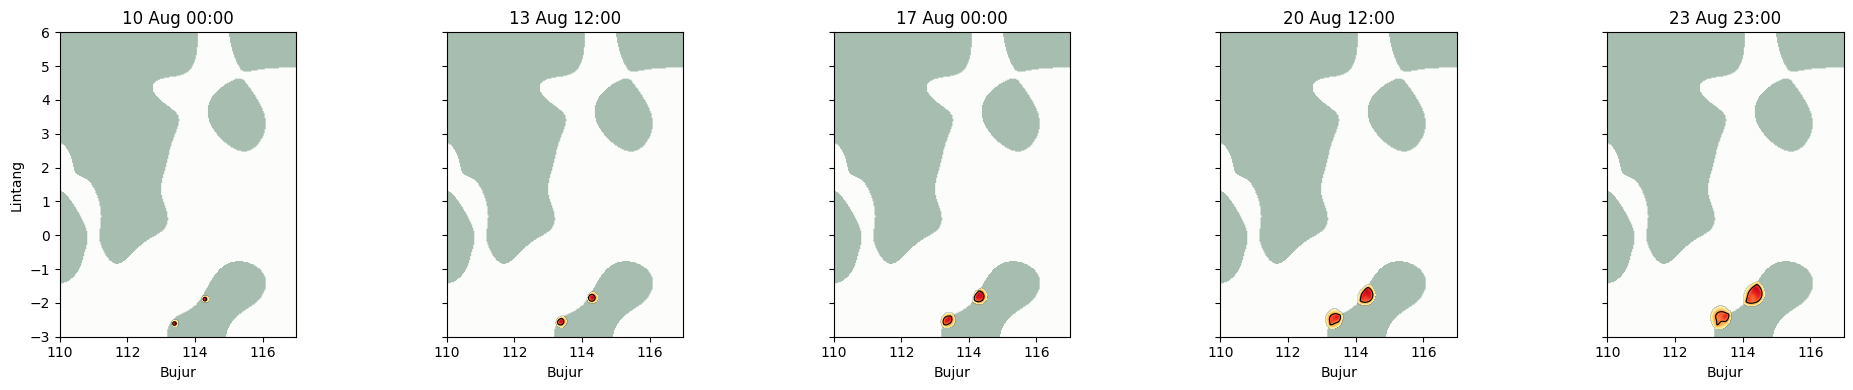

  gambar: fig1_front_sintetis.png


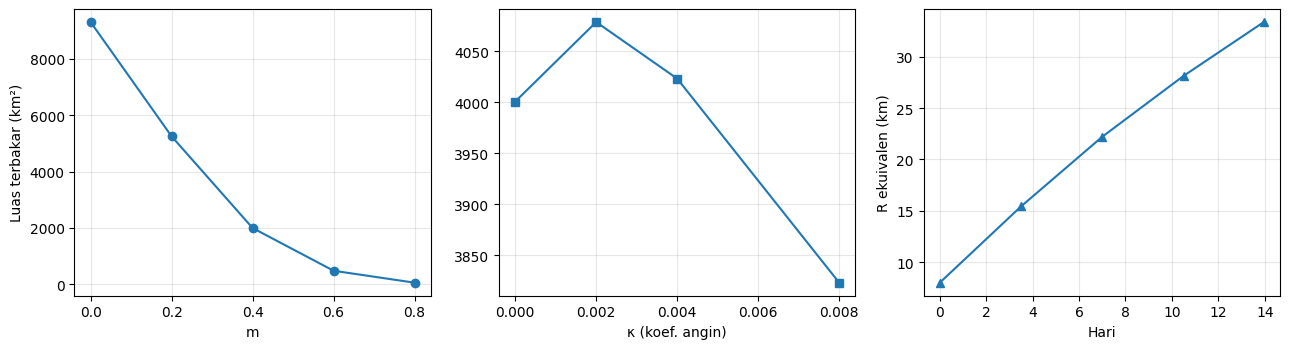

  gambar: fig2_sensitivitas_sintetis.png


In [10]:
hasil_sintetis = jalankan_sintetis()


=== TAHAP: validasi terhadap hotspot ===
swvl1: persentil 2 = 0.061, persentil 98 = 0.379 m3/m3  ->  m in [0,1]
hotspot: {'total': 66410, 'setelah_confidence_waktu': 62864, 'di_domain': 44143}
  kalibrasi 20/270
  kalibrasi 40/270
  kalibrasi 60/270
  kalibrasi 80/270
  kalibrasi 100/270
  kalibrasi 120/270
  kalibrasi 160/270
  kalibrasi 180/270
  kalibrasi 200/270
  kalibrasi 220/270
  kalibrasi 240/270
  kalibrasi 260/270

Parameter terbaik (v2):
 r             0.002000
D             0.050000
s0            0.010000
sigma_km      5.000000
alpha         4.000000
J             0.758705
Dice          0.798117
absln_area    0.078824

                       uji_Dice  uji_IoU   RMSE_km2      R2  v_fire_km_per_hari
v2                       0.750    0.599   6043.307  -1.194               2.295
tanpa_suku_penyalaan     0.770    0.625  10292.019  -5.363               2.745
tanpa_kelembapan         0.752    0.603  27902.993 -45.772               3.550
persistensi              0.596    0.425  3

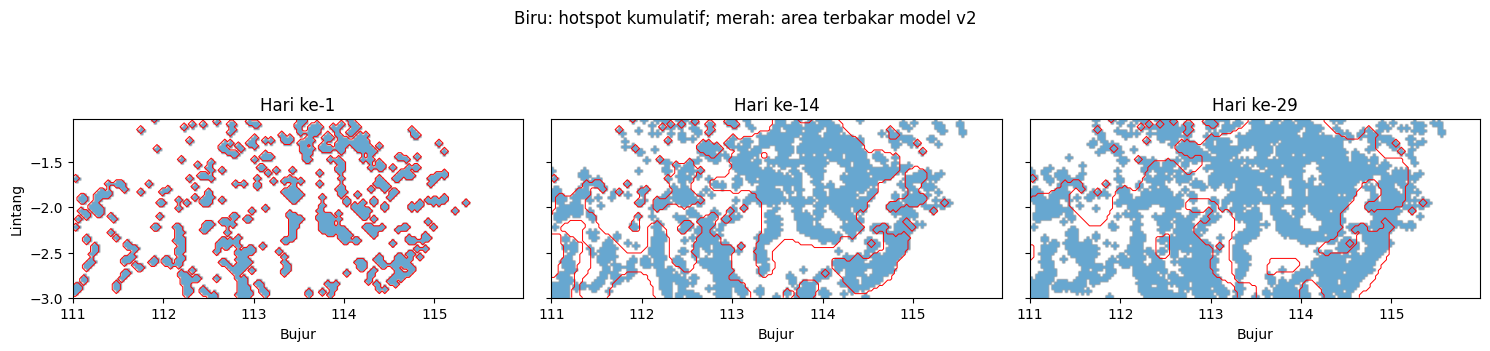

  gambar: fig_validasi_peta.png


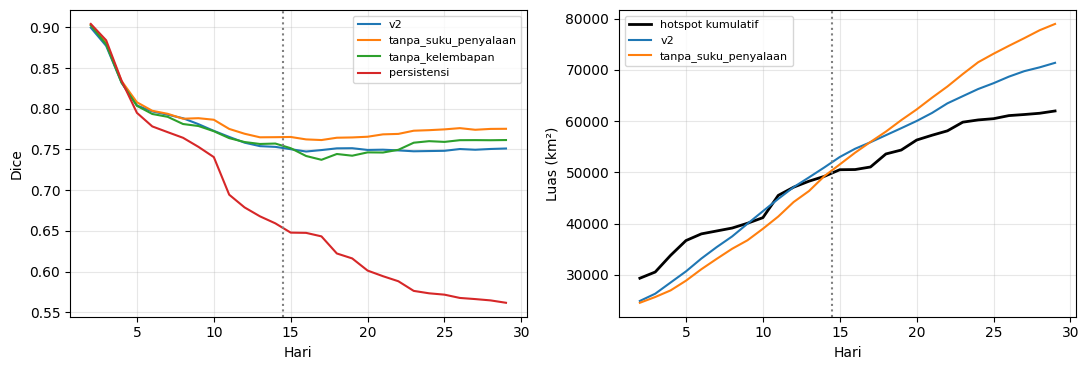

  gambar: fig_validasi_metrik.png


In [11]:
CEPAT = False
hasil_validasi = jalankan_validasi(cepat=CEPAT)

## 8. Catatan interpretasi
* Mask gambut pada tahap sintetis adalah **sintetis**; pada validasi `G = 1` seragam karena
  `Indonesia_peat_lands.csv` tidak memuat koordinat. Rasterisasi shapefile asli dengan `rasterisasi_gambut`.
* Hotspot adalah anomali termal titik, bukan batas area terbakar; luas "hotspot kumulatif" bergantung pada buffer sel.
* Parameter dikalibrasi pada 14 hari pertama dan diuji pada 14 hari berikutnya di satu wilayah; generalisasi belum teruji.